# Fine-tune `yolo11n-pose` trên `mapo80/DocCornerDataset` & Benchmark So sánh (Google Colab)

Notebook này giúp bạn:
1. Tải và chuyển đổi bộ dữ liệu `mapo80/DocCornerDataset` (48,265 ảnh: `train`, `validation`, `test`, bao gồm cả mẫu âm `is_negative=True`) sang định dạng **YOLO-Pose** (`1 class: document`, `4 keypoints: TL, TR, BR, BL`).
2. Đánh giá các baseline **TRƯỚC khi fine-tune**:
   - **Classical OpenCV**: Thuật toán xử lý ảnh cổ điển từ `src/core/detector.py` (`Auto-Canny` + `Otsu Paper Mask` + `approxPolyDP` + `full-frame/minAreaRect fallback`).
   - **Existing AI (`deeplabv3_mbv3_docseg.onnx`, tùy chọn)**: Model segmentation hiện có trong repo (tự động chạy nếu bạn upload file `.onnx` lên Colab hoặc Google Drive).
   - **YOLO11n-pose Pretrained (Before Fine-tuning)**: Trọng số gốc COCO `yolo11n-pose.pt` (trước khi học bài toán tìm góc tài liệu).
3. Fine-tune **`yolo11n-pose`** trên GPU Colab, export sang **`.onnx`** tối ưu cho `onnxruntime` CPU.
4. Đánh giá model **SAU khi fine-tune** (cả `.pt` trên GPU và `.onnx` trên CPU), xuất bảng so sánh, biểu đồ và ảnh trực quan.

---

### Bộ 4 Metric Cốt lõi (Gọn cho Báo cáo)
Để bảng số liệu và biểu đồ trong báo cáo trực quan, không bị rối và công bằng giữa OpenCV cổ điển, Segmentation ONNX và `yolo11n-pose`, notebook chỉ giữ lại **4 chỉ số quan trọng nhất**:

| Metric | Hướng tốt | Ý nghĩa trong Báo cáo |
|---|---|---|
| **`mIoU (%)`** | Càng **cao** càng tốt (`0–100%`) | **Độ khớp vùng giấy:** Tỷ lệ diện tích chồng lấp giữa tứ giác 4 góc dự đoán và tứ giác thực tế trên các ảnh có tài liệu (bỏ sót tính `0%`). |
| **`F1-Score (%)`** | Càng **cao** càng tốt (`0–100%`) | **Độ chính xác phát hiện tài liệu:** Điểm F1 tổng hợp cả Precision & Recall (đạt `IoU >= 0.50` trên ảnh có giấy và không báo nhầm trên ảnh âm `is_negative=True`). |
| **`Corner Error NME (%)`** | Càng **thấp** càng tốt (`0–100%`) | **Sai số tọa độ 4 góc:** Khoảng cách Euclid trung bình từ 4 góc dự đoán tới 4 góc thật (% so với kích thước ảnh, dùng Hungarian matching 1-1; bỏ sót tính `100%`). |
| **`Latency (ms)`** | Càng **thấp** càng nhanh (`ms/ảnh`) | **Tốc độ xử lý:** Thời gian trung bình để suy luận 1 ảnh. |


## 1. Kiểm tra GPU & Cài đặt thư viện


In [20]:
!nvidia-smi


Mon Nov 23 04:19:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   52C    P0             29W /   72W |     794MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [21]:
%pip install -q ultralytics datasets shapely scipy onnx onnxslim onnxruntime pandas matplotlib seaborn tqdm


In [22]:
import torch
import ultralytics
import onnxruntime as ort

print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Ultralytics: {ultralytics.__version__}")
print(f"ONNX Runtime providers: {ort.get_available_providers()}")


PyTorch: 2.14.1+cu130 | CUDA available: True
GPU: NVIDIA L4
Ultralytics: 8.4.216
ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


## 2. Cấu hình & Kết nối Google Drive
Bạn có thể chỉnh `MAX_TRAIN_SAMPLES = 10000` nếu muốn chạy thử nhanh, hoặc giữ `None` để train toàn bộ `32,968` ảnh.
Nếu muốn benchmark luôn model `models/deeplabv3_mbv3_docseg.onnx` hiện tại của repo, hãy upload file đó lên `/content/deeplabv3_mbv3_docseg.onnx` hoặc thư mục `DRIVE_SAVE_DIR` trên Google Drive.


In [23]:
import os
import json
import time
import shutil
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# ==================== CẤU HÌNH TRUNG TÂM & TỐI ƯU COLAB PRO ====================
USE_GOOGLE_DRIVE = True
WORK_DIR = Path("/content/doc_corner_yolo")
DRIVE_SAVE_DIR = Path("/content/drive/MyDrive/miniCamscanner_yolo11n_pose")

EXISTING_ONNX_CANDIDATES = [
    Path("/content/deeplabv3_mbv3_docseg.onnx"),
    DRIVE_SAVE_DIR / "deeplabv3_mbv3_docseg.onnx",
]

# Đặt None để dùng toàn bộ dataset; hoặc đặt số nguyên (vd: 10000) để test nhanh
MAX_TRAIN_SAMPLES = None      # Full = 32,968
MAX_VAL_SAMPLES = None        # Full = 8,645
MAX_TEST_EVAL_SAMPLES = 500   # Tập con phân tầng (stratified) để benchmark nhanh & công bằng; đặt None để chạy cả 6,652 ảnh test

EPOCHS = 30
IMG_SIZE = 640
CONF_THRESHOLD = 0.25
SEED = 42

# Tự động nhận diện GPU VRAM & System RAM (hỗ trợ T4 / L4 / A100 / High-RAM trên Colab Pro)
CPU_COUNT = os.cpu_count() or 2
WORKERS = min(8, CPU_COUNT)
SYS_RAM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / (1024 ** 3)

if torch.cuda.is_available():
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    if GPU_VRAM_GB >= 38:       # A100 40GB / 80GB
        BATCH_SIZE = 128
    elif GPU_VRAM_GB >= 20:     # L4 24GB
        BATCH_SIZE = 64
    else:                       # T4 / V100 16GB
        BATCH_SIZE = 32
else:
    GPU_NAME = "CPU"
    GPU_VRAM_GB = 0.0
    BATCH_SIZE = 16

# Cache vào RAM nếu dùng Colab Pro High-RAM (>= 40GB) để loại bỏ nghẽn đọc đĩa khi train
CACHE_MODE = "ram" if SYS_RAM_GB >= 40 else False

print(
    f"Phần cứng: GPU={GPU_NAME} ({GPU_VRAM_GB:.1f} GB VRAM) | "
    f"RAM={SYS_RAM_GB:.1f} GB | CPU={CPU_COUNT} cores\n"
    f"Auto-config: BATCH_SIZE={BATCH_SIZE}, WORKERS={WORKERS}, CACHE_MODE={CACHE_MODE}"
)
# ==============================================================================

random.seed(SEED)
np.random.seed(SEED)
WORK_DIR.mkdir(parents=True, exist_ok=True)

DRIVE_MOUNTED = False
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)
        DRIVE_MOUNTED = True
        print(f"Đã kết nối Google Drive. Thư mục lưu kết quả: {DRIVE_SAVE_DIR}")
    except Exception as exc:
        print(f"Không mount được Google Drive ({exc}). Kết quả sẽ lưu cục bộ tại {WORK_DIR}.")


Phần cứng: GPU=NVIDIA L4 (22.0 GB VRAM) | RAM=53.0 GB | CPU=12 cores
Auto-config: BATCH_SIZE=64, WORKERS=8, CACHE_MODE=ram
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã kết nối Google Drive. Thư mục lưu kết quả: /content/drive/MyDrive/miniCamscanner_yolo11n_pose


## 3. Tải `mapo80/DocCornerDataset` & Chuyển đổi sang YOLO-Pose
- Mỗi mẫu có 4 góc theo thứ tự chiều kim đồng hồ: `TL -> TR -> BR -> BL`.
- Lưu ý quan trọng: Khi augmentation lật ngang (`fliplr`), `TL <-> TR` và `BR <-> BL` phải đổi chỗ cho nhau, do đó `data.yaml` bắt buộc khai báo `flip_idx: [1, 0, 3, 2]` và tắt lật dọc (`flipud: 0.0`).
- Các mẫu `is_negative=True` được ghi ra file label `.txt` rỗng theo chuẩn Ultralytics.


In [24]:
from datasets import load_dataset, Image as HFImage

print("Đang tải dataset mapo80/DocCornerDataset từ Hugging Face...")
hf_dataset = load_dataset("mapo80/DocCornerDataset")

for split_name in ["train", "validation", "test"]:
    ds_split = hf_dataset[split_name]
    neg_count = sum(1 for x in ds_split["is_negative"] if x)
    pos_count = len(ds_split) - neg_count
    print(f"Split '{split_name}': {len(ds_split):,} ảnh (Positive: {pos_count:,} | Negative: {neg_count:,})")


Đang tải dataset mapo80/DocCornerDataset từ Hugging Face...


Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Split 'train': 32,968 ảnh (Positive: 29,089 | Negative: 3,879)
Split 'validation': 8,645 ảnh (Positive: 7,625 | Negative: 1,020)
Split 'test': 6,652 ảnh (Positive: 5,866 | Negative: 786)


In [25]:
import io
from PIL import Image as PILImage

CORNER_KEYS = [
    "corner_tl_x", "corner_tl_y",
    "corner_tr_x", "corner_tr_y",
    "corner_br_x", "corner_br_y",
    "corner_bl_x", "corner_bl_y",
]


def _save_image_fast(img_info, img_path: Path):
    if img_path.exists():
        return
    raw_bytes = img_info.get("bytes") if isinstance(img_info, dict) else None
    if raw_bytes:
        # Ghi thẳng JPEG bytes gốc không cần decode/re-encode (nhanh gấp ~10-20x)
        if raw_bytes[:3] == b"\xff\xd8\xff":
            img_path.write_bytes(raw_bytes)
            return
        with PILImage.open(io.BytesIO(raw_bytes)) as pil_img:
            pil_img.convert("RGB").save(img_path, format="JPEG", quality=95)
    elif isinstance(img_info, dict) and img_info.get("path"):
        with PILImage.open(img_info["path"]) as pil_img:
            pil_img.convert("RGB").save(img_path, format="JPEG", quality=95)
    else:
        img_info.convert("RGB").save(img_path, format="JPEG", quality=95)


def export_split_to_yolo_pose(ds_split, target_split_name: str, max_samples=None):
    img_dir = WORK_DIR / "images" / target_split_name
    lbl_dir = WORK_DIR / "labels" / target_split_name
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    total = len(ds_split) if max_samples is None else min(len(ds_split), max_samples)
    # Tắt auto-decode ảnh để xuất song song tốc độ cao
    ds_raw = ds_split.select(range(total)).cast_column("image", HFImage(decode=False))

    manifest_records = [None] * total
    pos_exported, neg_exported = 0, 0
    chunk_size = 2000
    max_workers = min(16, CPU_COUNT * 2)

    def _write_one(task):
        img_info, img_path, lbl_path, lbl_content = task
        _save_image_fast(img_info, img_path)
        if not lbl_path.exists():
            lbl_path.write_text(lbl_content)

    with ThreadPoolExecutor(max_workers=max_workers) as pool, tqdm(total=total, desc=f"Exporting {target_split_name}") as pbar:
        for start in range(0, total, chunk_size):
            end = min(total, start + chunk_size)
            write_tasks = []
            for idx in range(start, end):
                sample = ds_raw[idx]
                stem = f"{target_split_name}_{idx:06d}"
                img_path = img_dir / f"{stem}.jpg"
                lbl_path = lbl_dir / f"{stem}.txt"

                raw_vals = [sample[k] for k in CORNER_KEYS]
                is_neg = bool(sample["is_negative"]) or any(
                    v is None or (isinstance(v, float) and np.isnan(v)) for v in raw_vals
                )

                corners_norm = None
                lbl_content = ""
                if not is_neg:
                    coords = np.clip(np.array(raw_vals, dtype=np.float32).reshape(4, 2), 0.0, 1.0)
                    x_min, y_min = coords[:, 0].min(), coords[:, 1].min()
                    x_max, y_max = coords[:, 0].max(), coords[:, 1].max()
                    bw = float(x_max - x_min)
                    bh = float(y_max - y_min)
                    if bw < 1e-4 or bh < 1e-4:
                        is_neg = True
                    else:
                        xc = float((x_min + x_max) / 2.0)
                        yc = float((y_min + y_max) / 2.0)
                        kpt_str = " ".join(f"{x:.6f} {y:.6f} 2" for x, y in coords)
                        lbl_content = f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f} {kpt_str}\n"
                        corners_norm = coords.tolist()
                        pos_exported += 1

                if is_neg:
                    neg_exported += 1

                write_tasks.append((sample["image"], img_path, lbl_path, lbl_content))
                manifest_records[idx] = {
                    "image_path": str(img_path),
                    "filename": sample["filename"],
                    "is_negative": bool(is_neg),
                    "corners_norm": corners_norm,
                }

            list(pool.map(_write_one, write_tasks))
            pbar.update(end - start)

    print(f"[{target_split_name}] Đã xuất {total:,} ảnh (Positive: {pos_exported:,} | Negative: {neg_exported:,})")
    return manifest_records


train_records = export_split_to_yolo_pose(hf_dataset["train"], "train", MAX_TRAIN_SAMPLES)
val_records = export_split_to_yolo_pose(hf_dataset["validation"], "val", MAX_VAL_SAMPLES)
test_records_full = export_split_to_yolo_pose(hf_dataset["test"], "test", None)

# Tạo tập test_manifest phân tầng (stratified) giữ nguyên tỷ lệ Positive / Negative
if MAX_TEST_EVAL_SAMPLES is not None and MAX_TEST_EVAL_SAMPLES < len(test_records_full):
    rng = random.Random(SEED)
    pos_recs = [r for r in test_records_full if not r["is_negative"]]
    neg_recs = [r for r in test_records_full if r["is_negative"]]
    pos_ratio = len(pos_recs) / len(test_records_full)
    n_pos = max(1, int(round(MAX_TEST_EVAL_SAMPLES * pos_ratio)))
    n_neg = min(len(neg_recs), MAX_TEST_EVAL_SAMPLES - n_pos)
    test_manifest = rng.sample(pos_recs, min(n_pos, len(pos_recs))) + rng.sample(neg_recs, n_neg)
    rng.shuffle(test_manifest)
else:
    test_manifest = test_records_full

TEST_MANIFEST_PATH = WORK_DIR / "test_manifest.json"
TEST_MANIFEST_PATH.write_text(json.dumps(test_manifest, indent=2))
print(
    f"Đã lưu test_manifest ({len(test_manifest)} ảnh: "
    f"{sum(not r['is_negative'] for r in test_manifest)} positive, "
    f"{sum(r['is_negative'] for r in test_manifest)} negative) tại {TEST_MANIFEST_PATH}"
)

DATA_YAML_PATH = WORK_DIR / "data.yaml"
DATA_YAML_PATH.write_text(
    f"path: {WORK_DIR}\n"
    f"train: images/train\n"
    f"val: images/val\n"
    f"test: images/test\n\n"
    f"kpt_shape: [4, 3]\n"
    f"flip_idx: [1, 0, 3, 2]\n\n"
    f"names:\n"
    f"  0: document\n"
)
print(f"Đã tạo {DATA_YAML_PATH}")


Exporting train:   0%|          | 0/32968 [00:00<?, ?it/s]

[train] Đã xuất 32,968 ảnh (Positive: 29,089 | Negative: 3,879)


Exporting val:   0%|          | 0/8645 [00:00<?, ?it/s]

[val] Đã xuất 8,645 ảnh (Positive: 7,625 | Negative: 1,020)


Exporting test:   0%|          | 0/6652 [00:00<?, ?it/s]

[test] Đã xuất 6,652 ảnh (Positive: 5,866 | Negative: 786)
Đã lưu test_manifest (500 ảnh: 441 positive, 59 negative) tại /content/doc_corner_yolo/test_manifest.json
Đã tạo /content/doc_corner_yolo/data.yaml


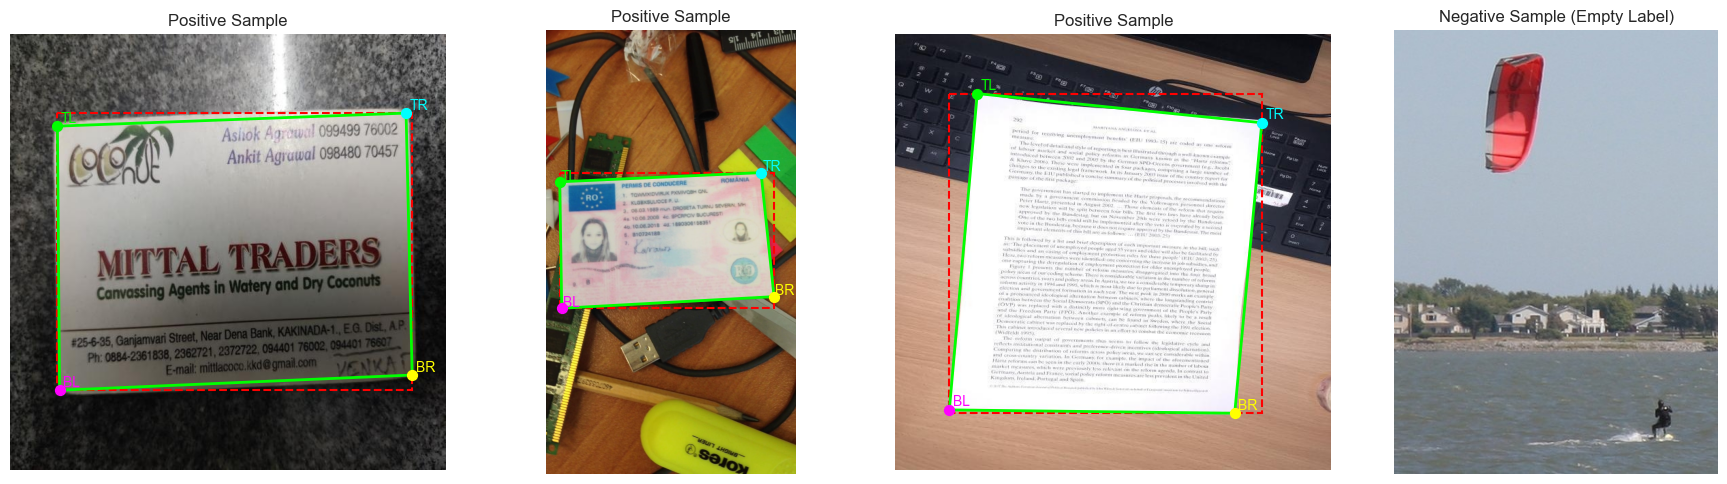

In [26]:
# Kiểm tra trực quan 4 mẫu (3 positive + 1 negative) trực tiếp từ file nhãn YOLO vừa sinh
pos_samples = [r for r in train_records if not r["is_negative"]][:3]
neg_samples = [r for r in train_records if r["is_negative"]][:1]
check_samples = pos_samples + neg_samples

fig, axes = plt.subplots(1, len(check_samples), figsize=(18, 5))
corner_names = ["TL", "TR", "BR", "BL"]
corner_colors = ["lime", "cyan", "yellow", "magenta"]

for ax, rec in zip(axes, check_samples):
    img_rgb = cv2.cvtColor(cv2.imread(rec["image_path"]), cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    lbl_path = Path(rec["image_path"].replace("/images/", "/labels/")).with_suffix(".txt")
    lbl_text = lbl_path.read_text().strip()

    ax.imshow(img_rgb)
    if lbl_text:
        parts = [float(x) for x in lbl_text.split()]
        xc, yc, bw, bh = parts[1:5]
        x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        rect = plt.Rectangle((x1, y1), bw * w, bh * h, fill=False, edgecolor="red", linewidth=1.5, linestyle="--")
        ax.add_patch(rect)

        kpts = np.array(parts[5:]).reshape(4, 3)[:, :2]
        kpts_px = kpts * np.array([w, h])
        poly = plt.Polygon(kpts_px, fill=False, edgecolor="lime", linewidth=2)
        ax.add_patch(poly)
        for idx, (kx, ky) in enumerate(kpts_px):
            ax.scatter(kx, ky, c=corner_colors[idx], s=50, zorder=5)
            ax.text(kx + 5, ky - 5, corner_names[idx], color=corner_colors[idx], fontsize=10, fontweight="bold")
        ax.set_title("Positive Sample")
    else:
        ax.set_title("Negative Sample (Empty Label)")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. Xây dựng Bộ Metric Đánh giá Thống nhất
Mọi detector đều trả về cùng một định dạng `(corners_norm, detected_bool, extra)`:
- `corners_norm`: mảng `(4, 2)` chuẩn hóa `[0, 1]` hoặc `None` nếu không phát hiện được tài liệu.
- `detected_bool`: `True` nếu model tự tin có tài liệu (không phải fallback mặc định của OpenCV), `False` nếu không có.


In [27]:
from shapely.geometry import Polygon
from scipy.optimize import linear_sum_assignment


def order_quad_cyclic(pts: np.ndarray) -> np.ndarray:
    """Sắp xếp 4 điểm theo góc cực quanh tâm để tránh đa giác tự cắt khi tính IoU."""
    pts = np.asarray(pts, dtype=np.float64).reshape(4, 2)
    center = pts.mean(axis=0)
    angles = np.arctan2(pts[:, 1] - center[1], pts[:, 0] - center[0])
    return pts[np.argsort(angles)]


def compute_polygon_iou(pred_norm, gt_norm) -> float:
    if pred_norm is None or gt_norm is None:
        return 0.0
    try:
        poly_pred = Polygon(order_quad_cyclic(pred_norm)).buffer(0)
        poly_gt = Polygon(order_quad_cyclic(gt_norm)).buffer(0)
        if not poly_pred.is_valid or not poly_gt.is_valid or poly_pred.area <= 0 or poly_gt.area <= 0:
            return 0.0
        inter = poly_pred.intersection(poly_gt).area
        union = poly_pred.union(poly_gt).area
        return float(inter / union) if union > 0 else 0.0
    except Exception:
        return 0.0


def compute_corner_nme(pred_norm: np.ndarray, gt_norm: np.ndarray) -> float:
    """Sai số Euclid chuẩn hóa [0, 1] trung bình 4 góc (Hungarian 1-to-1 matching)."""
    pred_pts = np.asarray(pred_norm, dtype=np.float64).reshape(4, 2)
    gt_pts = np.asarray(gt_norm, dtype=np.float64).reshape(4, 2)
    dist_matrix = np.linalg.norm(pred_pts[:, None, :] - gt_pts[None, :, :], axis=2)
    row_ind, col_ind = linear_sum_assignment(dist_matrix)
    return float(dist_matrix[row_ind, col_ind].mean())


def evaluate_detector(model_name: str, predict_fn, manifest: list, warmup: int = 3):
    if len(manifest) > 0:
        sample_img = cv2.imread(manifest[0]["image_path"])
        for _ in range(min(warmup, len(manifest))):
            _ = predict_fn(sample_img)

    per_sample = []
    latencies_ms = []

    tp = fp = tn = fn = 0
    pos_ious = []
    pos_nmes = []

    for rec in tqdm(manifest, desc=f"Evaluating {model_name}"):
        img_bgr = cv2.imread(rec["image_path"])
        t0 = time.perf_counter()
        pred_norm, detected, extra = predict_fn(img_bgr)
        dt_ms = (time.perf_counter() - t0) * 1000.0
        latencies_ms.append(dt_ms)

        is_neg = bool(rec["is_negative"])
        gt_norm = None if is_neg else np.asarray(rec["corners_norm"], dtype=np.float32)

        if not is_neg:
            if pred_norm is not None:
                iou = compute_polygon_iou(pred_norm, gt_norm)
                nme = compute_corner_nme(pred_norm, gt_norm)
            else:
                iou = 0.0
                nme = 1.0  # Phạt sai số tối đa 1.0 (100%) nếu bỏ sót ảnh có tài liệu

            pos_ious.append(iou)
            pos_nmes.append(nme)

            # Tính F1 tại ngưỡng phát hiện đúng vùng tài liệu (IoU >= 0.50)
            if detected and iou >= 0.50:
                tp += 1
            else:
                fn += 1
                if detected and iou < 0.50:
                    fp += 1
        else:
            if detected:
                fp += 1
            else:
                tn += 1
            iou = np.nan
            nme = np.nan

        per_sample.append({
            "filename": rec["filename"],
            "image_path": rec["image_path"],
            "is_negative": is_neg,
            "detected": bool(detected),
            "pred_norm": None if pred_norm is None else np.asarray(pred_norm, dtype=np.float32).tolist(),
            "gt_norm": None if gt_norm is None else gt_norm.tolist(),
            "iou": iou,
            "nme": nme,
            "latency_ms": dt_ms,
        })

    pos_ious_arr = np.asarray(pos_ious, dtype=np.float64)
    pos_nmes_arr = np.asarray(pos_nmes, dtype=np.float64)
    precision = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
    recall = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    f1_score = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    mean_lat = float(np.mean(latencies_ms))

    summary = {
        "Model": model_name,
        "mIoU (%)": float(np.mean(pos_ious_arr) * 100.0) if len(pos_ious_arr) else 0.0,
        "F1-Score (%)": float(f1_score * 100.0),
        "Corner Error NME (%)": float(np.mean(pos_nmes_arr) * 100.0) if len(pos_nmes_arr) else 100.0,
        "Latency (ms)": mean_lat,
    }
    return summary, per_sample


## 5. Đánh giá các Baseline TRƯỚC khi Fine-tune
Gồm 3 baseline:
1. **Classical OpenCV** (chép chính xác logic từ `src/core/detector.py` + `order_points` từ `src/core/transform.py`).
   - Khi `is_fallback=True` (OpenCV không tìm được tứ giác hợp lệ phải fallback về `minAreaRect` hoặc viền 2%), ta ghi nhận `detected=False` để tính đúng `Pos Recall` / `Neg FPR`, nhưng vẫn giữ `pred_norm` để đo `IoU` thực tế nếu muốn xem fallback tệ đến mức nào.
2. **Existing AI (`deeplabv3_mbv3_docseg.onnx`)** (chỉ chạy nếu tìm thấy file `.onnx` trong Colab/Drive).
3. **YOLO11n-pose Pretrained (`yolo11n-pose.pt`)** — baseline trước khi fine-tune. (Lưu ý: weights gốc COCO chỉ được train cho dáng người 17 keypoints, chưa biết nhận diện tài liệu).


In [28]:
# 5.1 Port chính xác thuật toán OpenCV cổ điển từ src/core/detector.py & src/core/transform.py

def order_points(pts):
    pts = np.array(pts, dtype="float32")
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect


def auto_canny(image, sigma=0.33):
    v = np.median(image)
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    return cv2.Canny(image, lower, upper)


def _extract_quad_from_mask(mask, new_w, canonical_height, min_area_ratio=0.15):
    padded = cv2.copyMakeBorder(mask, 2, 2, 2, 2, cv2.BORDER_CONSTANT, value=0)
    contours, _ = cv2.findContours(padded, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:5]
    min_area = (new_w * canonical_height) * min_area_ratio
    for c in contours:
        if cv2.contourArea(c) < min_area:
            continue
        for geom in [c, cv2.convexHull(c)]:
            peri = cv2.arcLength(geom, True)
            for eps_factor in [0.02, 0.03, 0.04, 0.05, 0.06, 0.08]:
                approx = cv2.approxPolyDP(geom, eps_factor * peri, True)
                if len(approx) == 4 and cv2.isContourConvex(approx):
                    pts = np.clip(approx.reshape(4, 2) - 2, [0, 0], [new_w - 1, canonical_height - 1])
                    return pts.reshape(4, 1, 2)
    return None


def predict_classical_opencv(img_bgr, canonical_height=800):
    orig_h, orig_w = img_bgr.shape[:2]
    ratio = orig_h / float(canonical_height)
    new_w = max(1, int(orig_w / ratio))

    resized = cv2.resize(img_bgr, (new_w, canonical_height), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.bilateralFilter(gray, d=9, sigmaColor=75, sigmaSpace=75)
    edged = auto_canny(blurred)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    closed = cv2.morphologyEx(edged, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(closed.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

    min_area = (new_w * canonical_height) * 0.10
    target_contour = None

    # Chiến lược 1: Auto-Canny + approxPolyDP
    for c in contours:
        if cv2.contourArea(c) < min_area:
            continue
        peri = cv2.arcLength(c, True)
        for eps_factor in [0.02, 0.03, 0.04]:
            approx = cv2.approxPolyDP(c, eps_factor * peri, True)
            if len(approx) == 4 and cv2.isContourConvex(approx):
                target_contour = approx
                break
        if target_contour is not None:
            break

    # Chiến lược 2: Otsu Paper Mask
    if target_contour is None:
        k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
        paper_bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k_close)
        _, otsu = cv2.threshold(paper_bg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        clean_mask = cv2.morphologyEx(otsu, cv2.MORPH_OPEN, k_open)
        target_contour = _extract_quad_from_mask(clean_mask, new_w, canonical_height)

    # Chiến lược 3: Full-frame & Fallback
    is_fallback = False
    is_full_frame = False
    if target_contour is None:
        borders = np.concatenate([gray[0, :], gray[-1, :], gray[:, 0], gray[:, -1]])
        if np.mean(borders > 160) > 0.6:
            is_full_frame = True
            target_contour = np.array([
                [0, 0], [new_w - 1, 0], [new_w - 1, canonical_height - 1], [0, canonical_height - 1]
            ], dtype=np.int32).reshape(4, 1, 2)
        elif len(contours) > 0 and cv2.contourArea(contours[0]) >= min_area:
            is_fallback = True
            rect = cv2.minAreaRect(contours[0])
            target_contour = np.int32(cv2.boxPoints(rect)).reshape(4, 1, 2)
        else:
            is_fallback = True
            mx, my = int(new_w * 0.02), int(canonical_height * 0.02)
            target_contour = np.array([
                [mx, my], [new_w - mx, my], [new_w - mx, canonical_height - my], [mx, canonical_height - my]
            ], dtype=np.int32).reshape(4, 1, 2)

    corners_px = order_points(target_contour.reshape(4, 2).astype("float32") * ratio)
    corners_norm = np.clip(corners_px / np.array([orig_w, orig_h], dtype=np.float32), 0.0, 1.0)
    detected = not is_fallback
    return corners_norm, detected, {"is_fallback": is_fallback, "is_full_frame": is_full_frame}


In [29]:
# 5.2 Chạy benchmark các baseline TRƯỚC khi fine-tune
from ultralytics import YOLO

benchmark_summaries = []
benchmark_details = {}

# 1) Classical OpenCV
sum_cv, det_cv = evaluate_detector("Classical OpenCV (Repo)", predict_classical_opencv, test_manifest)
benchmark_summaries.append(sum_cv)
benchmark_details["Classical OpenCV (Repo)"] = det_cv

# 2) Existing DeepLabV3 ONNX (nếu người dùng có upload sẵn)
existing_onnx_path = next((p for p in EXISTING_ONNX_CANDIDATES if p.exists()), None)
if existing_onnx_path is not None:
    print(f"Tìm thấy model AI hiện tại: {existing_onnx_path} -> Đang chạy benchmark...")
    seg_session = ort.InferenceSession(str(existing_onnx_path), providers=["CPUExecutionProvider"])
    seg_in_meta = seg_session.get_inputs()[0]
    seg_shape = seg_in_meta.shape
    seg_h = seg_shape[2] if isinstance(seg_shape[2], int) else 384
    seg_w = seg_shape[3] if isinstance(seg_shape[3], int) else 384
    seg_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    seg_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def predict_existing_onnx(img_bgr, canonical_height=800):
        orig_h, orig_w = img_bgr.shape[:2]
        ratio = orig_h / float(canonical_height)
        new_w = max(1, int(orig_w / ratio))
        resized = cv2.resize(img_bgr, (new_w, canonical_height), interpolation=cv2.INTER_AREA)

        rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
        blob = cv2.resize(rgb, (seg_w, seg_h)).astype(np.float32) / 255.0
        blob = (blob - seg_mean) / seg_std
        blob = np.transpose(blob, (2, 0, 1))[None, ...]
        pred = np.squeeze(seg_session.run(None, {seg_in_meta.name: blob})[0])
        if pred.ndim == 3 and pred.shape[0] > 1:
            prob = np.argmax(pred, axis=0).astype(np.float32)
        else:
            if pred.ndim == 3:
                pred = pred[0]
            prob = (pred - pred.min()) / (pred.max() - pred.min() + 1e-8)

        mask = (cv2.resize(prob, (new_w, canonical_height)) > 0.5).astype(np.uint8) * 255
        k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k_open)
        quad = _extract_quad_from_mask(mask, new_w, canonical_height)
        if quad is None:
            return None, False, {}
        corners_px = order_points(quad.reshape(4, 2).astype("float32") * ratio)
        corners_norm = np.clip(corners_px / np.array([orig_w, orig_h], dtype=np.float32), 0.0, 1.0)
        return corners_norm, True, {}

    sum_seg, det_seg = evaluate_detector("DeepLabV3-Seg ONNX (Repo)", predict_existing_onnx, test_manifest)
    benchmark_summaries.append(sum_seg)
    benchmark_details["DeepLabV3-Seg ONNX (Repo)"] = det_seg
else:
    print(
        "Bỏ qua DeepLabV3-Seg ONNX vì chưa thấy file 'deeplabv3_mbv3_docseg.onnx'.\n"
        f"(Nếu muốn so sánh thêm model này, hãy upload lên {EXISTING_ONNX_CANDIDATES[0]} rồi chạy lại cell.)"
    )

# 3) YOLO11n-pose Pretrained (trước khi fine-tune)
pretrained_yolo = YOLO("yolo11n-pose.pt")


def make_yolo_pt_predictor(yolo_model, conf_thr=CONF_THRESHOLD):
    use_half = torch.cuda.is_available()

    def _predict(img_bgr):
        results = yolo_model.predict(img_bgr, imgsz=IMG_SIZE, conf=conf_thr, half=use_half, verbose=False)
        res = results[0]
        if res.boxes is None or len(res.boxes) == 0 or res.keypoints is None or res.keypoints.xyn is None:
            return None, False, {}
        kpts_xyn = res.keypoints.xyn
        if len(kpts_xyn) == 0 or kpts_xyn.shape[1] < 4:
            return None, False, {}
        best_idx = int(res.boxes.conf.argmax().item())
        pts = kpts_xyn[best_idx][:4].cpu().numpy().astype(np.float32)
        return np.clip(pts, 0.0, 1.0), True, {"conf": float(res.boxes.conf[best_idx].item())}
    return _predict


sum_pre, det_pre = evaluate_detector(
    "YOLO11n-pose Pretrained (Before)",
    make_yolo_pt_predictor(pretrained_yolo),
    test_manifest,
)
benchmark_summaries.append(sum_pre)
benchmark_details["YOLO11n-pose Pretrained (Before)"] = det_pre

pd.DataFrame(benchmark_summaries).set_index("Model").round(4)


Evaluating Classical OpenCV (Repo):   0%|          | 0/500 [00:00<?, ?it/s]

Bỏ qua DeepLabV3-Seg ONNX vì chưa thấy file 'deeplabv3_mbv3_docseg.onnx'.
(Nếu muốn so sánh thêm model này, hãy upload lên /content/deeplabv3_mbv3_docseg.onnx rồi chạy lại cell.)
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Evaluating YOLO11n-pose Pretrained (Before):   0%|          | 0/500 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,mIoU (%),F1-Score (%),Corner Error NME (%),Latency (ms)
Model,,,,
Classical OpenCV (Repo),63.9893,64.7059,15.6863,75.7962
YOLO11n-pose Pretrained (Before),0.1169,0.0000,74.0610,16.2625


## 6. Fine-tune `yolo11n-pose` trên `mapo80/DocCornerDataset`
Sử dụng augmentation hình học nhẹ (`degrees`, `perspective`, `scale`, `fliplr`) và ánh sáng (`hsv_*`) để tăng độ bền vững với các góc chụp thực tế. `flipud` được đặt `0.0` để bảo toàn thứ tự trên-dưới của nhãn.


In [11]:
model = YOLO("yolo11n-pose.pt")

train_results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=WORKERS,
    cache=CACHE_MODE,
    amp=True,
    patience=10,
    optimizer="AdamW",
    lr0=1e-3,
    lrf=0.01,
    cos_lr=True,
    degrees=15.0,
    translate=0.1,
    scale=0.3,
    shear=5.0,
    perspective=0.0005,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,
    mosaic=0.5,
    close_mosaic=10,
    project=str(WORK_DIR / "runs"),
    name="yolo11n_pose_doccorner",
    exist_ok=True,
    seed=SEED,
)

RUN_DIR = WORK_DIR / "runs" / "yolo11n_pose_doccorner"
BEST_PT_PATH = RUN_DIR / "weights" / "best.pt"
print(f"Huấn luyện hoàn tất! Best weights: {BEST_PT_PATH}")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/doc_corner_yolo/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-pose.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11n_pose_doccorner, nbs=64, nms=None, opset=N

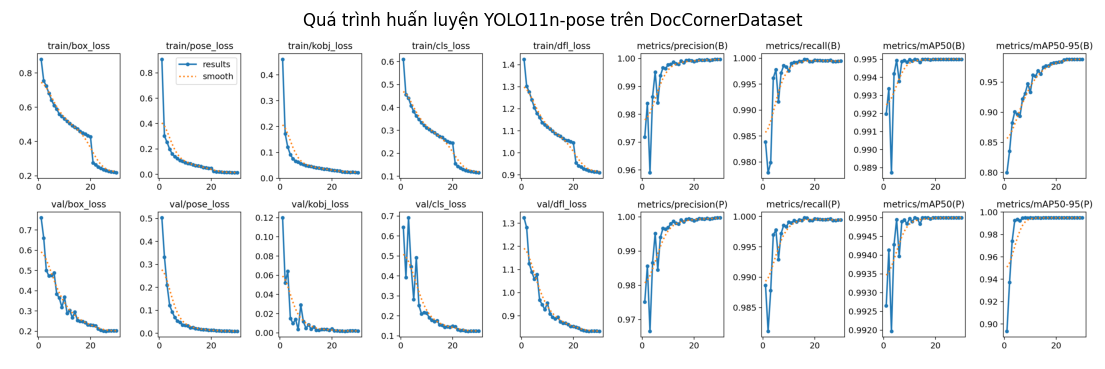

In [12]:
results_png = RUN_DIR / "results.png"
if results_png.exists():
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(cv2.imread(str(results_png)), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Quá trình huấn luyện YOLO11n-pose trên DocCornerDataset")
    plt.show()


## 7. Export ONNX & Đánh giá Model SAU khi Fine-tune
Export sang `yolo11n_doc_corner.onnx` (opset 12, `simplify=True`) và dùng class `YoloPoseOnnxDetector` thuần `cv2 + numpy + onnxruntime` để đo cùng bộ 4 metric (`mIoU (%)`, `F1-Score (%)`, `Corner Error NME (%)`, `Latency (ms)`) giống hệt các baseline.


In [13]:
best_model = YOLO(str(BEST_PT_PATH))

# Export sang ONNX
exported_onnx_path = Path(
    best_model.export(format="onnx", imgsz=IMG_SIZE, opset=12, simplify=True, dynamic=False)
)
FINAL_ONNX_PATH = WORK_DIR / "yolo11n_doc_corner.onnx"
shutil.copy2(exported_onnx_path, FINAL_ONNX_PATH)
print(f"Đã export ONNX: {FINAL_ONNX_PATH} ({FINAL_ONNX_PATH.stat().st_size / 1e6:.2f} MB)")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-pose summary (fused): 109 layers, 2,654,479 parameters, 0 gradients, 6.6 GFLOPs

PyTorch: starting from '/content/doc_corner_yolo/runs/yolo11n_pose_doccorner/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 17, 8400) (5.4 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.5s, saved as '/content/doc_corner_yolo/runs/yolo11n_pose_doccorner/weights/best.onnx' (10.5 MB)

Export complete (4.3s)
Results saved to /content/doc_corner_yolo/runs/yolo11n_pose_doccorner/weights/best.onnx
Predict:         yolo predict task=pose model=/content/doc_corner_yolo/runs/yolo11n_pose_doccorner/weights/best.onnx imgsz=640 
Validate:        yolo val task=pose model=/content/doc_

In [14]:
class YoloPoseOnnxDetector:
    """Detector thuần OpenCV + NumPy + ONNX Runtime tối ưu cho CPU (dùng được ngay trong miniCamscanner)."""

    def __init__(self, onnx_path: str, img_size: int = 640, conf_threshold: float = 0.25, num_threads: int = 4):
        sess_opts = ort.SessionOptions()
        sess_opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
        sess_opts.intra_op_num_threads = max(1, min(num_threads, os.cpu_count() or 4))
        self.session = ort.InferenceSession(str(onnx_path), sess_options=sess_opts, providers=["CPUExecutionProvider"])
        self.input_name = self.session.get_inputs()[0].name
        self.img_size = img_size
        self.conf_threshold = conf_threshold

    def _letterbox(self, img_bgr):
        h, w = img_bgr.shape[:2]
        scale = min(self.img_size / h, self.img_size / w)
        nw, nh = int(round(w * scale)), int(round(h * scale))
        resized = cv2.resize(img_bgr, (nw, nh), interpolation=cv2.INTER_LINEAR)
        pad_w = (self.img_size - nw) / 2.0
        pad_h = (self.img_size - nh) / 2.0
        top, bottom = int(round(pad_h - 0.1)), int(round(pad_h + 0.1))
        left, right = int(round(pad_w - 0.1)), int(round(pad_w + 0.1))
        canvas = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        return canvas, scale, left, top

    def __call__(self, img_bgr):
        orig_h, orig_w = img_bgr.shape[:2]
        canvas, scale, pad_x, pad_y = self._letterbox(img_bgr)
        # cv2.dnn.blobFromImage gộp BGR->RGB, chia 255 và HWC->NCHW bằng C++ (nhanh hơn NumPy)
        blob = cv2.dnn.blobFromImage(canvas, scalefactor=1.0 / 255.0, swapRB=True, crop=False)

        out = self.session.run(None, {self.input_name: blob})[0]
        out = np.squeeze(out, axis=0)
        if out.shape[0] < out.shape[1]:
            out = out.T  # Đưa về dạng (N_anchors, 4 + 1 + 4*3 = 17)

        scores = out[:, 4]
        best_idx = int(np.argmax(scores))
        best_score = float(scores[best_idx])
        if best_score < self.conf_threshold:
            return None, False, {"conf": best_score}

        kpts_raw = out[best_idx, 5:17].reshape(4, 3)[:, :2]
        kpts_px = (kpts_raw - np.array([pad_x, pad_y], dtype=np.float32)) / scale
        kpts_norm = np.clip(kpts_px / np.array([orig_w, orig_h], dtype=np.float32), 0.0, 1.0)
        return kpts_norm, True, {"conf": best_score}


# Benchmark YOLO11n-pose Fine-tuned (.pt GPU/CPU)
sum_ft_pt, det_ft_pt = evaluate_detector(
    "YOLO11n-pose Fine-tuned (.pt)",
    make_yolo_pt_predictor(best_model),
    test_manifest,
)
benchmark_summaries.append(sum_ft_pt)
benchmark_details["YOLO11n-pose Fine-tuned (.pt)"] = det_ft_pt

# Benchmark YOLO11n-pose Fine-tuned (.onnx CPU)
onnx_detector = YoloPoseOnnxDetector(FINAL_ONNX_PATH, img_size=IMG_SIZE, conf_threshold=CONF_THRESHOLD)
sum_ft_onnx, det_ft_onnx = evaluate_detector(
    "YOLO11n-pose Fine-tuned (.onnx CPU)",
    onnx_detector,
    test_manifest,
)
benchmark_summaries.append(sum_ft_onnx)
benchmark_details["YOLO11n-pose Fine-tuned (.onnx CPU)"] = det_ft_onnx


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Evaluating YOLO11n-pose Fine-tuned (.pt):   0%|          | 0/500 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

Evaluating YOLO11n-pose Fine-tuned (.onnx CPU):   0%|          | 0/500 [00:00<?, ?it/s]

## 8. Bảng Tổng hợp 4 Metric Cốt lõi & Biểu đồ Báo cáo


In [15]:
df_summary = pd.DataFrame(benchmark_summaries).set_index("Model")
CSV_PATH = WORK_DIR / "benchmark_comparison.csv"
df_summary.to_csv(CSV_PATH)
print(f"Đã lưu bảng so sánh tại: {CSV_PATH}")

display_cols = [
    "mIoU (%)",
    "F1-Score (%)",
    "Corner Error NME (%)",
    "Latency (ms)",
]
df_summary[display_cols].round(2)


Đã lưu bảng so sánh tại: /content/doc_corner_yolo/benchmark_comparison.csv


,mIoU (%),F1-Score (%),Corner Error NME (%),Latency (ms)
Model,,,,
Classical OpenCV (Repo),63.99,64.71,15.69,74.74
YOLO11n-pose Pretrained (Before),0.12,0.00,74.06,78.55
YOLO11n-pose Fine-tuned (.pt),89.86,97.59,4.79,28.54
YOLO11n-pose Fine-tuned (.onnx CPU),90.34,97.59,4.32,35.14


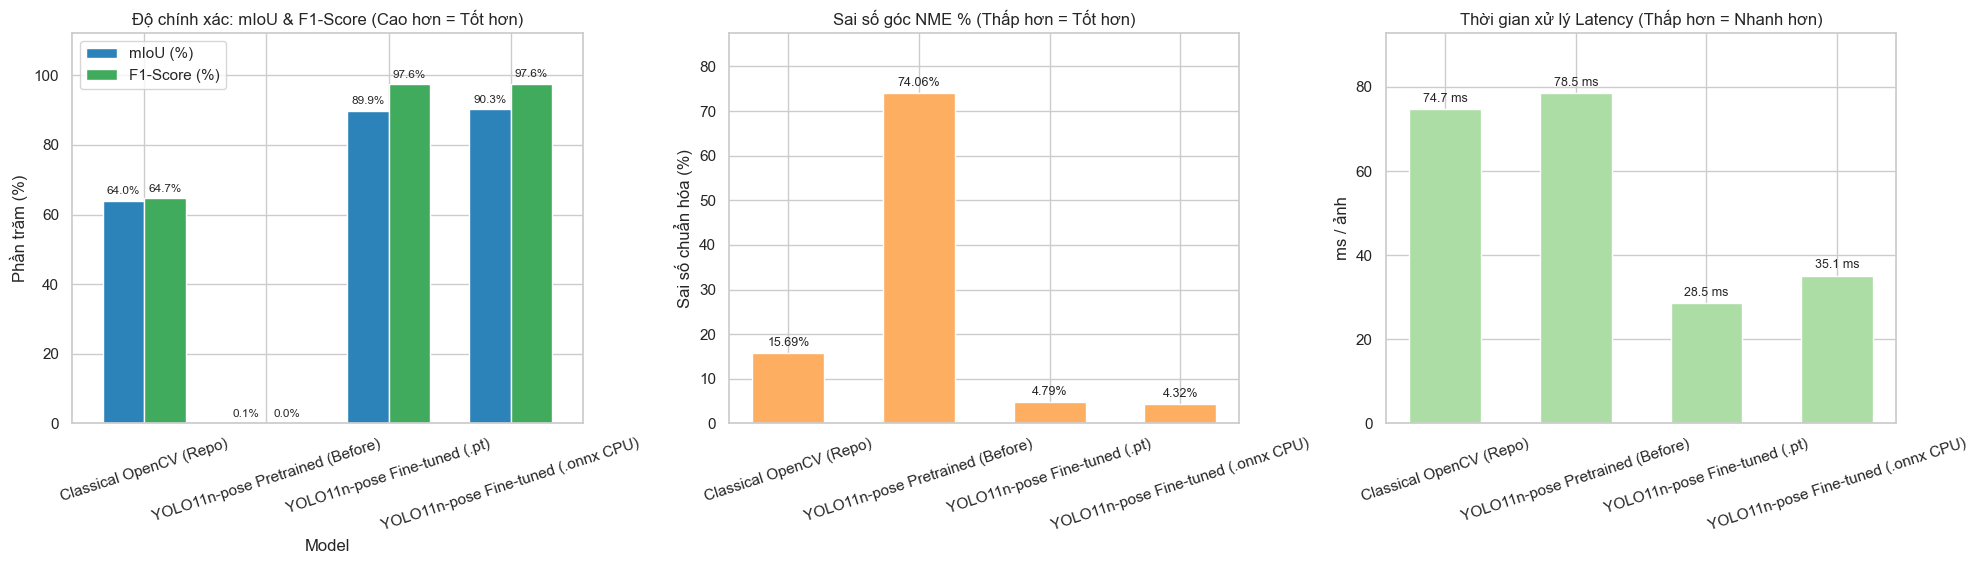

In [16]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# 1. Độ chính xác: mIoU (%) & F1-Score (%) (càng cao càng tốt)
acc_df = df_summary[["mIoU (%)", "F1-Score (%)"]]
acc_df.plot(kind="bar", ax=axes[0], width=0.68, color=["#2b83ba", "#41ab5d"])
axes[0].set_title("Độ chính xác: mIoU & F1-Score (Cao hơn = Tốt hơn)", fontweight="bold")
axes[0].set_ylabel("Phần trăm (%)")
axes[0].set_ylim(0, 112)
axes[0].tick_params(axis="x", rotation=18)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=8.5)

# 2. Sai số tọa độ góc: Corner Error NME (%) (càng thấp càng tốt)
nme_series = df_summary["Corner Error NME (%)"]
bars_nme = axes[1].bar(nme_series.index, nme_series.values, color="#fdae61", width=0.55)
axes[1].set_title("Sai số góc NME % (Thấp hơn = Tốt hơn)", fontweight="bold")
axes[1].set_ylabel("Sai số chuẩn hóa (%)")
axes[1].set_ylim(0, max(float(nme_series.max()) * 1.18, 10.0))
axes[1].tick_params(axis="x", rotation=18)
axes[1].bar_label(bars_nme, fmt="%.2f%%", padding=3, fontsize=9)

# 3. Tốc độ xử lý: Latency (ms/ảnh) (càng thấp càng nhanh)
lat_series = df_summary["Latency (ms)"]
bars_lat = axes[2].bar(lat_series.index, lat_series.values, color="#abdda4", width=0.55)
axes[2].set_title("Thời gian xử lý Latency (Thấp hơn = Nhanh hơn)", fontweight="bold")
axes[2].set_ylabel("ms / ảnh")
axes[2].set_ylim(0, max(float(lat_series.max()) * 1.18, 10.0))
axes[2].tick_params(axis="x", rotation=18)
axes[2].bar_label(bars_lat, fmt="%.1f ms", padding=3, fontsize=9)

plt.tight_layout()
CHARTS_PATH = WORK_DIR / "benchmark_charts.png"
plt.savefig(CHARTS_PATH, dpi=150, bbox_inches="tight")
plt.show()


## 9. So sánh Trực quan trên Ảnh Test
Hiển thị 6 ảnh Positive (ưu tiên các ca khó mà OpenCV cổ điển có IoU thấp) và 2 ảnh Negative để so sánh trực tiếp đường viền 4 góc giữa:
- **Xanh lá (Ground Truth)**
- **Xanh dương (Classical OpenCV)**
- **Cam (YOLO11n-pose Pretrained hoặc DeepLabV3 nếu có)**
- **Đỏ (YOLO11n-pose Fine-tuned .onnx)**


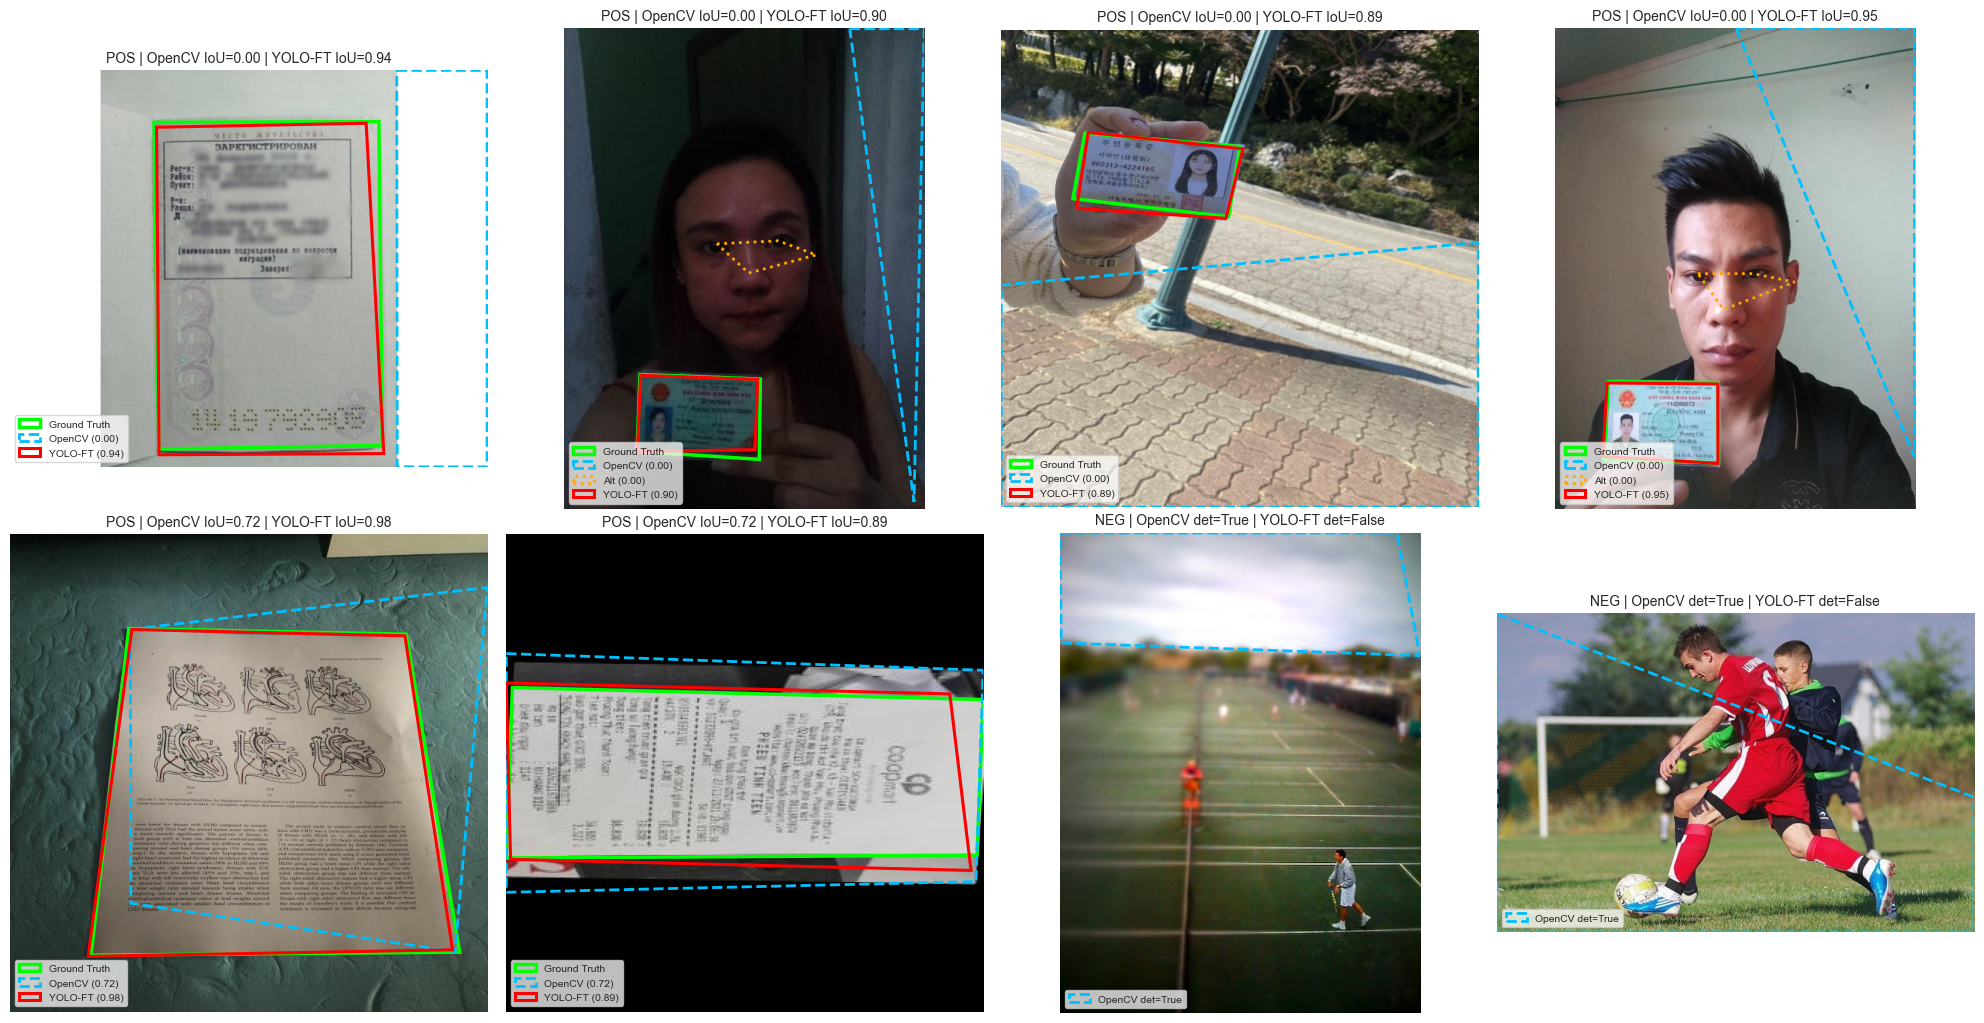

In [17]:
cv_list = benchmark_details["Classical OpenCV (Repo)"]
ft_list = benchmark_details["YOLO11n-pose Fine-tuned (.onnx CPU)"]
alt_key = "DeepLabV3-Seg ONNX (Repo)" if "DeepLabV3-Seg ONNX (Repo)" in benchmark_details else "YOLO11n-pose Pretrained (Before)"
alt_list = benchmark_details[alt_key]

# Chọn 4 ca khó nhất của Classical OpenCV + 2 ca trung bình + 2 ca Negative
pos_indices = [i for i, d in enumerate(cv_list) if not d["is_negative"]]
pos_sorted_by_cv_iou = sorted(pos_indices, key=lambda i: cv_list[i]["iou"])
hard_idx = pos_sorted_by_cv_iou[:4]
mid_idx = pos_sorted_by_cv_iou[len(pos_sorted_by_cv_iou) // 2 : len(pos_sorted_by_cv_iou) // 2 + 2]
neg_idx = [i for i, d in enumerate(cv_list) if d["is_negative"]][:2]
selected_indices = hard_idx + mid_idx + neg_idx


def draw_quad(ax, pts_norm, w, h, color, label, linestyle="-", lw=2.0):
    if pts_norm is None:
        return
    pts_px = order_quad_cyclic(np.array(pts_norm)) * np.array([w, h])
    poly = plt.Polygon(pts_px, fill=False, edgecolor=color, linewidth=lw, linestyle=linestyle, label=label)
    ax.add_patch(poly)


cols = 4
rows = int(np.ceil(len(selected_indices) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(20, 5.2 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, idx in zip(axes, selected_indices):
    rec_cv = cv_list[idx]
    rec_alt = alt_list[idx]
    rec_ft = ft_list[idx]

    img_rgb = cv2.cvtColor(cv2.imread(rec_cv["image_path"]), cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    ax.imshow(img_rgb)

    if not rec_cv["is_negative"]:
        draw_quad(ax, rec_cv["gt_norm"], w, h, "lime", "Ground Truth", lw=2.5)
        draw_quad(ax, rec_cv["pred_norm"], w, h, "deepskyblue", f"OpenCV ({rec_cv['iou']:.2f})", linestyle="--", lw=2.0)
        draw_quad(ax, rec_alt["pred_norm"], w, h, "orange", f"Alt ({rec_alt['iou']:.2f})", linestyle=":", lw=2.0)
        draw_quad(ax, rec_ft["pred_norm"], w, h, "red", f"YOLO-FT ({rec_ft['iou']:.2f})", lw=2.2)
        ax.set_title(
            f"POS | OpenCV IoU={rec_cv['iou']:.2f} | YOLO-FT IoU={rec_ft['iou']:.2f}",
            fontsize=10,
        )
    else:
        draw_quad(ax, rec_cv["pred_norm"], w, h, "deepskyblue", f"OpenCV det={rec_cv['detected']}", linestyle="--")
        draw_quad(ax, rec_ft["pred_norm"], w, h, "red", f"YOLO-FT det={rec_ft['detected']}")
        ax.set_title(
            f"NEG | OpenCV det={rec_cv['detected']} | YOLO-FT det={rec_ft['detected']}",
            fontsize=10,
        )

    ax.legend(loc="lower left", fontsize=7.5, framealpha=0.75)
    ax.axis("off")

for ax in axes[len(selected_indices):]:
    ax.axis("off")

plt.tight_layout()
VISUAL_PATH = WORK_DIR / "visual_comparison.png"
plt.savefig(VISUAL_PATH, dpi=150, bbox_inches="tight")
plt.show()


## 10. Lưu kết quả vào Google Drive & Tải về
Sau khi tải `yolo11n_doc_corner.onnx` về máy, bạn có thể đặt vào thư mục `models/yolo11n_doc_corner.onnx` của project `miniCamscanner`.


In [18]:
artifacts = [
    BEST_PT_PATH,
    FINAL_ONNX_PATH,
    CSV_PATH,
    CHARTS_PATH,
    VISUAL_PATH,
]

if DRIVE_MOUNTED:
    for src_file in artifacts:
        if src_file.exists():
            dst_file = DRIVE_SAVE_DIR / src_file.name
            shutil.copy2(src_file, dst_file)
            print(f"Đã sao chép -> {dst_file}")
else:
    print("Google Drive chưa được mount. Các file kết quả hiện nằm tại:")
    for src_file in artifacts:
        print(f" - {src_file}")


Đã sao chép -> /content/drive/MyDrive/miniCamscanner_yolo11n_pose/best.pt
Đã sao chép -> /content/drive/MyDrive/miniCamscanner_yolo11n_pose/yolo11n_doc_corner.onnx
Đã sao chép -> /content/drive/MyDrive/miniCamscanner_yolo11n_pose/benchmark_comparison.csv
Đã sao chép -> /content/drive/MyDrive/miniCamscanner_yolo11n_pose/benchmark_charts.png
Đã sao chép -> /content/drive/MyDrive/miniCamscanner_yolo11n_pose/visual_comparison.png


In [19]:
# Tùy chọn: Bỏ comment dòng dưới để tải trực tiếp file ONNX về máy từ Colab
# from google.colab import files
# files.download(str(FINAL_ONNX_PATH))
